# Olist Marketing Funnel: EDA, Visualisation and Statistical Tests
**Notebook 2 of 2.** Notebook 1 (`Olist_Funnel_Analysis_Colab.ipynb`) checks and cleans the data and builds the KPI tables. This notebook is the analysis story: charts, outlier checks and statistical tests.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Saniya1312S/Olist-Marketing-Funnel-Lead-Conversion/blob/main/python/02_eda_and_visuals.ipynb)

**Business question:** *Which lead channels produce sellers, how long does a sale take, and which numbers can we trust?*

| Step | What | Why |
|---|---|---|
| 1 | Load and build one row per lead | Same logic as the SQL view `lead_master` |
| 2 | Data quality and outlier check | Know what can be trusted |
| 3 | Channel analysis (volume vs value) | Where should budget go? |
| 4 | Fair-period check (Jan-May 2018) | Early months are not comparable |
| 5 | Speed to close | When should sales follow up? |
| 6 | Statistical tests | Is the gap real or luck? |
| 7 | So what: findings and actions | Turn numbers into decisions |

## 1. Load the data and build one row per lead

In [1]:
import math, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
NAVY, BLUE, ORANGE, GREY, GREEN, RED = "#1F3864", "#2E75B6", "#ED7D31", "#A6A6A6", "#548235", "#C00000"

# Find the raw files: repo folder, Colab upload, or straight from GitHub
RAW_NAMES = ["olist_marketing_qualified_leads_dataset.csv", "olist_closed_deals_dataset.csv"]
for base in [Path("../data/raw"), Path("data/raw"), Path(".")]:
    if (base / RAW_NAMES[0]).exists():
        src = str(base) + "/"; break
else:
    src = "https://raw.githubusercontent.com/Saniya1312S/Olist-Marketing-Funnel-Lead-Conversion/main/data/raw/"
IMG = Path("../documents/images") if Path("../documents").exists() else Path("documents/images") if Path("documents").exists() else Path(".")
mql   = pd.read_csv(src + RAW_NAMES[0])
deals = pd.read_csv(src + RAW_NAMES[1])
print("Leads:", mql.shape, "| Closed deals:", deals.shape, "| read from:", src)

Leads: (8000, 4) | Closed deals: (842, 14) | read from: ../data/raw/


In [2]:
# One row per lead (a LEFT JOIN: every lead is kept, deals are added where they exist)
df = mql.merge(deals[["mql_id", "won_date", "lead_type", "business_segment", "lead_behaviour_profile"]],
               on="mql_id", how="left", validate="one_to_one")
df["origin"]             = df["origin"].fillna("not_provided")                   # blank origin kept, labelled
df["first_contact_date"] = pd.to_datetime(df["first_contact_date"])
df["won_day"]            = pd.to_datetime(df["won_date"]).dt.normalize()
df["converted"]          = df["won_day"].notna().astype(int)                     # target flag
df["days_to_close"]      = (df["won_day"] - df["first_contact_date"]).dt.days
df.loc[df["days_to_close"] < 0, "days_to_close"] = np.nan                        # 1 deal won before first contact
df["month"]  = df["first_contact_date"].dt.to_period("M").astype(str)
df["period"] = np.where(df["first_contact_date"] < "2018-01-01", "Jun-Dec 2017", "Jan-May 2018")
df["channel_group"] = df["origin"].map(lambda o: "Search" if o in ("organic_search", "paid_search")
                       else "Social + email" if o in ("social", "email")
                       else "Unknown / blank" if o in ("unknown", "not_provided") else "Other known")
fair = df[df["period"] == "Jan-May 2018"]          # the FAIR, comparable period
print(f"Overall conversion {df.converted.mean():.1%} | Jan-May 2018 {fair.converted.mean():.1%}")
df.head(3)

Overall conversion 10.5% | Jan-May 2018 13.0%


,mql_id,first_contact_date,landing_page_id,origin,won_date,lead_type,business_segment,lead_behaviour_profile,won_day,converted,days_to_close,month,period,channel_group
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social,NaN,NaN,NaN,NaN,NaT,0,NaN,2018-02,Jan-May 2018,Social + email
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search,NaN,NaN,NaN,NaN,NaT,0,NaN,2017-10,Jun-Dec 2017,Search
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search,NaN,NaN,NaN,NaN,NaT,0,NaN,2018-03,Jan-May 2018,Search


## 2. Data quality and outlier check
Nothing is deleted. Missing values get a label, never a guess.

In [3]:
quality = pd.Series({
    "Duplicate lead IDs":                       int(mql["mql_id"].duplicated().sum()),
    "Deals with no matching lead":              int((~deals["mql_id"].isin(mql["mql_id"])).sum()),
    "Leads with blank origin":                  int(mql["origin"].isna().sum()),
    "Deals missing behaviour profile":          int(deals["lead_behaviour_profile"].isna().sum()),
    "Deals won before first contact":           int((df["won_day"] < df["first_contact_date"]).sum()),
    "Questionnaire fields blank (avg %)":       round(deals[["has_company","has_gtin","average_stock","declared_product_catalog_size"]].isna().mean().mean()*100, 1),
    "Deals with declared revenue = 0 (%)":      round((deals["declared_monthly_revenue"] == 0).mean()*100, 1)})
quality

Duplicate lead IDs                       0.0
Deals with no matching lead              0.0
Leads with blank origin                 60.0
Deals missing behaviour profile        177.0
Deals won before first contact           1.0
Questionnaire fields blank (avg %)      92.2
Deals with declared revenue = 0 (%)     94.7
dtype: float64

In [4]:
# Outlier check on days_to_close with the IQR rule (a value above Q3 + 1.5 x IQR is an outlier)
d = df["days_to_close"].dropna()
q1, q3 = d.quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
print(f"mean {d.mean():.1f} | median {d.median():.0f} | skew {d.skew():.2f} | outlier fence {fence:.0f} days | "
      f"{(d > fence).sum()} slow outliers ({(d > fence).mean():.1%})")
print("Decision: they are real slow deals, so they are KEPT and reported separately. The MEDIAN is used as the typical value.")

mean 48.5 | median 14 | skew 2.29 | outlier fence 130 days | 105 slow outliers (12.5%)
Decision: they are real slow deals, so they are KEPT and reported separately. The MEDIAN is used as the typical value.


## 3. Channel analysis: volume is not value
A channel can bring many leads and very few sellers. The chart compares each group's **share of leads** with its **share of sign-ups**.

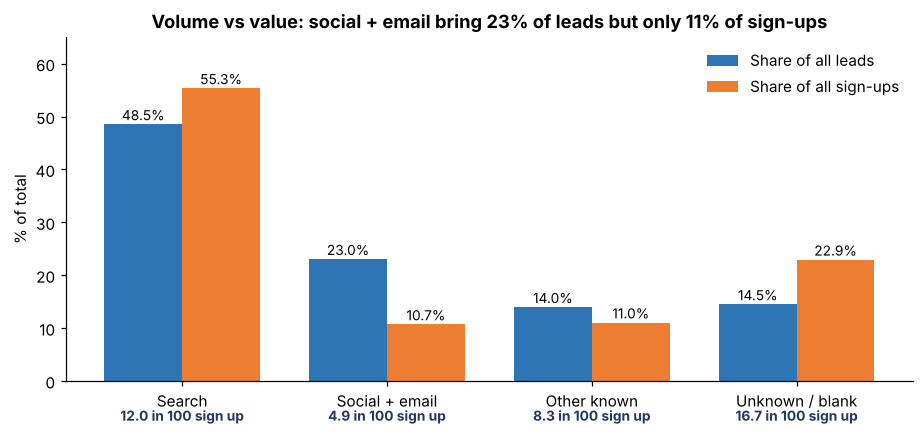

,leads,deals,share_leads,share_deals,conversion
channel_group,,,,,
Search,3882,466,48.5,55.3,12.0
Social + email,1843,90,23.0,10.7,4.9
Other known,1116,93,14.0,11.0,8.3
Unknown / blank,1159,193,14.5,22.9,16.7


In [5]:
g = (df.groupby("channel_group").agg(leads=("mql_id", "count"), deals=("converted", "sum")))
g["share_leads"] = g["leads"] / g["leads"].sum() * 100
g["share_deals"] = g["deals"] / g["deals"].sum() * 100
g["conversion"]  = g["deals"] / g["leads"] * 100
g = g.loc[["Search", "Social + email", "Other known", "Unknown / blank"]]

fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = np.arange(len(g)); w = 0.38
b1 = ax.bar(x - w/2, g["share_leads"], w, color=BLUE,   label="Share of all leads")
b2 = ax.bar(x + w/2, g["share_deals"], w, color=ORANGE, label="Share of all sign-ups")
for bars in (b1, b2):
    for r in bars: ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.8, f"{r.get_height():.1f}%", ha="center", fontsize=9)
for i, c in enumerate(g["conversion"]): ax.text(i, -7.5, f"{c:.1f} in 100 sign up", ha="center", fontsize=9, color=NAVY, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(g.index); ax.set_ylim(0, 65); ax.set_ylabel("% of total")
ax.set_title("Volume vs value: social + email bring 23% of leads but only 11% of sign-ups")
ax.legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.subplots_adjust(bottom=0.2)
plt.savefig(IMG / "chart5_volume_vs_value.png", bbox_inches="tight"); plt.show()
g.round(1)

## 4. Fair-period check: does the channel ranking survive?
Deal recording starts in **December 2017**, so leads from Jun-Dec 2017 look weak for a *data* reason (only 3% sign-up vs 13% from Jan 2018). If channel rates are recalculated on **Jan-May 2018 only**, do the conclusions change? Error bars show the 95% confidence interval (Wilson), so a small channel's wider range is visible.

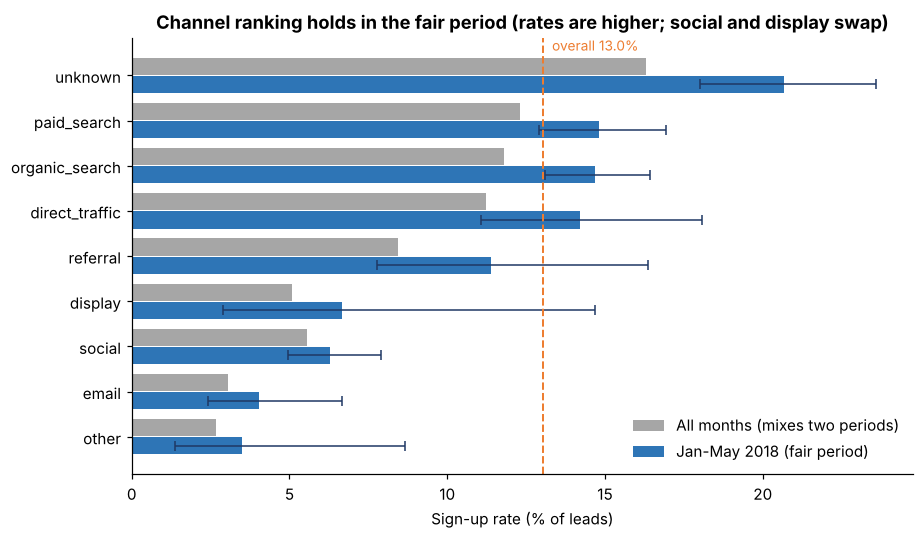

,origin,leads,conv_all,conv_fair,lo,hi
10,unknown,1099,16.3,20.7,18.0,23.6
7,paid_search,1586,12.3,14.8,12.9,16.9
4,organic_search,2296,11.8,14.7,13.1,16.4
0,direct_traffic,499,11.2,14.2,11.1,18.1
8,referral,284,8.5,11.4,7.8,16.4
1,display,118,5.1,6.7,2.9,14.7
9,social,1350,5.6,6.3,5.0,7.9
2,email,493,3.0,4.0,2.4,6.7
5,other,150,2.7,3.5,1.4,8.7


In [6]:
def wilson(x, n, z=1.96):
    p = x / n; den = 1 + z*z/n; c = (p + z*z/(2*n)) / den
    h = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / den
    return c - h, c + h

rows = []
for o, a in df.groupby("origin"):
    f = fair[fair["origin"] == o]
    lo, hi = wilson(f["converted"].sum(), len(f))
    rows.append(dict(origin=o, leads=len(a), conv_all=a["converted"].mean()*100,
                     leads_fair=len(f), conv_fair=f["converted"].mean()*100, lo=lo*100, hi=hi*100))
ch = pd.DataFrame(rows).sort_values("conv_fair", ascending=True)
ch = ch[ch["leads"] >= 100]                                   # leave out channels with under 100 leads

fig, ax = plt.subplots(figsize=(8.5, 5))
y = np.arange(len(ch))
ax.barh(y + 0.2, ch["conv_all"],  0.38, color=GREY, label="All months (mixes two periods)")
ax.barh(y - 0.2, ch["conv_fair"], 0.38, color=BLUE, label="Jan-May 2018 (fair period)",
        xerr=[ch["conv_fair"] - ch["lo"], ch["hi"] - ch["conv_fair"]], error_kw=dict(ecolor=NAVY, capsize=3, lw=1))
ax.axvline(fair["converted"].mean()*100, color=ORANGE, ls="--", lw=1.3)
ax.text(fair["converted"].mean()*100 + 0.3, len(ch) - 0.45, "overall 13.0%", color=ORANGE, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(ch["origin"]); ax.set_xlabel("Sign-up rate (% of leads)")
ax.set_title("Channel ranking holds in the fair period (rates are higher; social and display swap)")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout()
plt.savefig(IMG / "chart6_channel_robustness.png", bbox_inches="tight"); plt.show()
ch[["origin", "leads", "conv_all", "conv_fair", "lo", "hi"]].round(1).sort_values("conv_fair", ascending=False)

**Reading it.** The order of channels is almost unchanged (only social and display swap places, and display is a small channel), so the conclusion "search converts, social and email do not" does not depend on the weak early months. The absolute rates are higher in the fair period (search 14.7% instead of 12.0%).

**Unknown-source leads convert best (20.7%).** This is the opposite of a "bad data" group: the leads whose source is not tracked are among the most valuable. That makes fixing the tracking *more* important, not less. Do not read it as "unknown is a channel to buy more of".

## 5. Speed to close
Only closed deals have a days-to-close. Compare **all months** with the **fair period**.

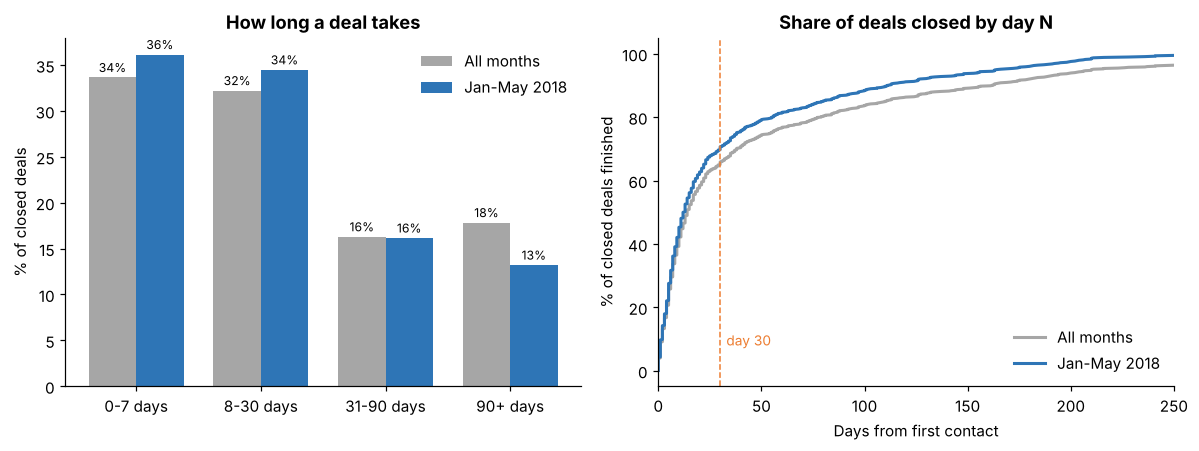

,All months,Jan-May 2018 (fair),Jun-Dec 2017
deals,841.0,780.0,61.0
mean days,48.5,35.7,212.2
median days,14.0,12.5,216.0
closed within 30 days %,65.9,70.6,4.9
over 90 days %,17.8,13.2,77.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bins = [0, 7, 30, 90, 450]; labels = ["0-7", "8-30", "31-90", "90+"]
allv, fv = df["days_to_close"].dropna(), fair["days_to_close"].dropna()
xx = np.arange(4); w = 0.38
a = pd.cut(allv, [-1, 7, 30, 90, 1e9], labels=labels).value_counts(normalize=True).reindex(labels) * 100
f = pd.cut(fv,   [-1, 7, 30, 90, 1e9], labels=labels).value_counts(normalize=True).reindex(labels) * 100
axes[0].bar(xx - w/2, a, w, color=GREY, label="All months"); axes[0].bar(xx + w/2, f, w, color=BLUE, label="Jan-May 2018")
for i, (p, q) in enumerate(zip(a, f)):
    axes[0].text(i - w/2, p + 0.6, f"{p:.0f}%", ha="center", fontsize=8); axes[0].text(i + w/2, q + 0.6, f"{q:.0f}%", ha="center", fontsize=8)
axes[0].set_xticks(xx); axes[0].set_xticklabels([l + " days" for l in labels]); axes[0].set_ylabel("% of closed deals")
axes[0].set_title("How long a deal takes"); axes[0].legend(frameon=False)

# Cumulative curve: share of closed deals finished by day N
for lab, v, col in [("All months", allv, GREY), ("Jan-May 2018", fv, BLUE)]:
    s = np.sort(v.values); axes[1].plot(s, np.arange(1, len(s) + 1) / len(s) * 100, color=col, lw=2, label=lab)
axes[1].axvline(30, color=ORANGE, ls="--", lw=1); axes[1].text(33, 8, "day 30", color=ORANGE, fontsize=9)
axes[1].set_xlim(0, 250); axes[1].set_xlabel("Days from first contact"); axes[1].set_ylabel("% of closed deals finished")
axes[1].set_title("Share of deals closed by day N"); axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(IMG / "chart7_days_to_close_fair.png", bbox_inches="tight"); plt.show()

summary = pd.DataFrame({lab: {"deals": len(v), "mean days": v.mean(), "median days": v.median(),
                              "closed within 30 days %": (v <= 30).mean()*100, "over 90 days %": (v > 90).mean()*100}
                        for lab, v in [("All months", allv), ("Jan-May 2018 (fair)", fv),
                                       ("Jun-Dec 2017", df[df.period == "Jun-Dec 2017"]["days_to_close"].dropna())]}).round(1)
summary

**Reading it.** The all-months numbers (average 48.5 days, 18% over 90 days) include 61 deals from Jun-Dec 2017 leads. Because deal recording only starts in Dec 2017, a lead from mid-2017 appears **only if it closed late** (median 216 days). Those few deals inflate the average.

**For planning, use the fair numbers:** median 12.5 days, about 7 in 10 close within 30 days, 13% take over 90 days. The all-months numbers are kept in the dashboard and report, and both views are stated.

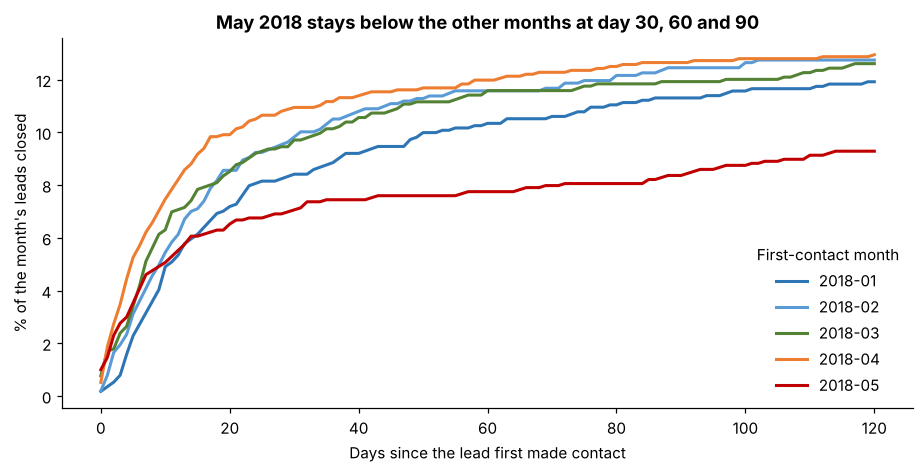

May 2018 actual 10.0% vs expected from channel mix 13.4%


In [8]:
# Cohort close curve: of the leads that arrived each month (Jan-May 2018), what share had closed by day N?
days = np.arange(0, 121)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for m, col in zip(sorted(fair["month"].unique()), [BLUE, "#5B9BD5", GREEN, ORANGE, RED]):
    s = fair[fair["month"] == m]
    ax.plot(days, [((s["days_to_close"] <= k).sum() / len(s)) * 100 for k in days], color=col, lw=2, label=m)
ax.set_xlabel("Days since the lead first made contact"); ax.set_ylabel("% of the month's leads closed")
ax.set_title("May 2018 stays below the other months at day 30, 60 and 90")
ax.legend(frameon=False, title="First-contact month"); plt.tight_layout()
plt.savefig(IMG / "chart8_cohort_close_curve.png", bbox_inches="tight"); plt.show()

# Is May just a change in channel mix? Expected conversion if every channel behaved as in Jan-Apr:
ref = fair[fair["month"] < "2018-05"].groupby("origin")["converted"].mean()
may = fair[fair["month"] == "2018-05"]
print(f"May 2018 actual {may.converted.mean():.1%} vs expected from channel mix {may['origin'].map(ref).mean():.1%}")

**Reading it.** May 2018 is lower even when compared on the same time window (day 60, day 90), and the channel mix does not explain it. This is a **question for the data owner**: did deal logging for May leads lag, or did lead quality drop? The data cannot answer it, and the finding is flagged rather than explained away.

## 6. Statistical tests: is the gap real or luck?
| Test | Question | Why this test |
|---|---|---|
| Chi-square | Is channel linked to sign-up? | Both are categories |
| Cramer's V | How strong is the link? | A significant p-value does not say how big the effect is |
| 95% confidence interval | How sure are we about a rate? | Small channels have wider ranges |
| Mann-Whitney / Kruskal-Wallis | Do wolf deals really take longer? | Days to close is skewed, so a non-parametric test is safer than a t-test |

In [9]:
def chi_overall(data):
    t = pd.crosstab(data["origin"], data["converted"]); chi2, p, dof, exp = chi2_contingency(t)
    return chi2, p, dof, math.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

for label, data in [("All months", df), ("Jan-May 2018", fair)]:
    chi2, p, dof, v = chi_overall(data)
    print(f"{label:<13} chi-square = {chi2:6.1f}, dof = {dof}, p = {p:.1e}, Cramer's V = {v:.2f}")

def head_to_head(data):
    s = data["origin"].isin(["organic_search", "paid_search"]); m = data["origin"].isin(["social", "email"])
    sw, sn, mw, mn = data[s].converted.sum(), s.sum(), data[m].converted.sum(), m.sum()
    chi2, p, _, _ = chi2_contingency(np.array([[sw, sn - sw], [mw, mn - mw]]), correction=False)
    (a, b), (c, d_) = wilson(sw, sn), wilson(mw, mn)
    return f"search {sw/sn:.1%} ({a:.1%} to {b:.1%}) vs social+email {mw/mn:.1%} ({c:.1%} to {d_:.1%}), chi-square = {chi2:.1f}, p = {p:.1e}"
print("\nSearch vs social + email")
print(" all months  :", head_to_head(df)); print(" Jan-May 2018:", head_to_head(fair))

# Wolf vs cat days to close
deal_rows = df[(df.converted == 1)].copy(); deal_rows["profile"] = deal_rows["lead_behaviour_profile"].fillna("Not Provided")
sg = deal_rows[deal_rows.profile.isin(["cat", "eagle", "wolf", "shark"])].dropna(subset=["days_to_close"])
grp = {k: v["days_to_close"].values for k, v in sg.groupby("profile")}
print("\nMedian days to close:", {k: float(np.median(v)) for k, v in grp.items()})
print(f"Mann-Whitney wolf vs cat p = {mannwhitneyu(grp['wolf'], grp['cat'])[1]:.1e} | Kruskal-Wallis (4 profiles) p = {kruskal(*grp.values())[1]:.1e}")

All months    chi-square =  140.7, dof = 10, p = 3.0e-25, Cramer's V = 0.13
Jan-May 2018  chi-square =  138.8, dof = 10, p = 7.6e-25, Cramer's V = 0.15

Search vs social + email
 all months  : search 12.0% (11.0% to 13.1%) vs social+email 4.9% (4.0% to 6.0%), chi-square = 72.3, p = 1.9e-17
 Jan-May 2018: search 14.7% (13.5% to 16.1%) vs social+email 5.7% (4.6% to 7.1%), chi-square = 73.7, p = 9.1e-18

Median days to close: {'cat': 13.0, 'eagle': 10.0, 'shark': 13.5, 'wolf': 36.0}
Mann-Whitney wolf vs cat p = 6.7e-05 | Kruskal-Wallis (4 profiles) p = 4.9e-05


**How to say it in an interview.**
- *Channel gap:* the chi-square p-value is far below 0.05 in both periods and the search and social+email ranges do not overlap, so the gap is not luck.
- *Effect size:* Cramer's V is about 0.13 to 0.15, a **modest** effect. Channel matters, but it is not the only driver of sign-up. This is why the recommendation is "review quality", not "cut social".
- *Patterns, not causes:* this is observational data. Search visitors may already be looking for a marketplace partner, and landing page and channel are tangled together.

## 7. So what? Findings and actions
| # | Finding | Evidence | Action |
|---|---|---|---|
| 1 | About 1 in 10 leads signs up | 842 of 8,000 (10.5%); 13.0% in the fair period | Use 13.0% as the benchmark |
| 2 | Search is the engine | 48.5% of leads, 55.3% of sign-ups; 14.7% conversion in Jan-May 2018 | Keep investing; check paid search cost first |
| 3 | Social and email bring volume, not sellers | 23% of leads, 10.7% of sign-ups; 5.7% conversion in Jan-May 2018 | Review lead quality and follow-up before adding budget |
| 4 | Untracked leads convert best | 14.5% of leads, 22.9% of sign-ups; 20.7% conversion in Jan-May 2018 | Fix source tracking (now the highest-value data fix) |
| 5 | The slow tail is partly a data artefact | Median 12.5 days, 70.6% within 30 days, 13.2% over 90 (fair period) vs 18% over 90 (all months) | Follow up at day 30; treat 90+ day deals separately |
| 6 | Wolf-profile deals are slower | Median 36 vs 13 (cat) and 10 (eagle) days, p < 0.001 | Earlier follow-up routine for wolf leads |
| 7 | May 2018 conversion dipped | 10.0% vs 13.4% expected; not explained by channel mix | Ask the data owner; monitor June onward |

**Limits.** No cost or revenue data (so no ROI or CAC), only two funnel stages, only closed deals have a days-to-close (right-censoring), and the data shows patterns, not causes.